# Lecture 11 - Imbalanced Datasets and Classification Model Calibration


# Introduction

The purpose of this notebook is to introduce two important techniques used in classification tasks: SMOTE (Synthetic Minority Over-sampling Technique) and model calibration. These methods address two common issues in applied machine learning: class imbalance and unreliable predicted probabilities.

We begin by using SMOTE to handle situations where one class is underrepresented in the data. This imbalance can lead classifiers to become biased toward the majority class, reducing sensitivity to minority-class patterns. SMOTE mitigates this by generating synthetic examples of the minority class, allowing the model to learn a more balanced decision boundary.

We then turn to calibration, which focuses not on which class is predicted, but on how confident the model is. Many classifiers output probability estimates that are poorly calibrated — especially under imbalanced or noisy conditions — meaning they over- or understate the true likelihood of their predictions. We will learn how to assess and correct this using techniques like Platt scaling and calibration curves.

By the end of this notebook, you will understand how to apply SMOTE to improve classifier fairness and how to calibrate a model’s probability outputs to make them more meaningful and trustworthy.

In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, cross_validate, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, brier_score_loss, roc_curve
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report
from sklearn.naive_bayes import GaussianNB

## Our small and imbalanced dataset

In [95]:
grades = pd.read_csv('../datasets/grades_prediction_mode.csv')
grades = grades.fillna(0)
print(grades.head() )
grades = grades.dropna()
grades


   Unnamed: 0   A1    A2   A3    A4    A5     CW  Exam  Total Grade Mode
0           0  3.5  5.50  7.5   6.5   7.5  30.50  30.0  60.50    B-  INT
1           1  2.5  4.50  3.2   3.8   0.0  14.00  10.0  24.00     E  INT
2           2  4.0  5.25  7.1  10.2  11.5  38.05  31.0  69.05     B  INT
3           3  4.0  0.00  3.0   7.7   9.5  24.20  23.0  47.20     R  INT
4           4  4.5  4.75  7.4  10.3   8.8  35.75  40.0  75.75    B+  EXT


,Unnamed: 0,A1,A2,A3,A4,A5,CW,Exam,Total,Grade,Mode
0,0,3.5,5.50,7.50,6.50,7.50,30.50,30.0,60.50,B-,INT
1,1,2.5,4.50,3.20,3.80,0.00,14.00,10.0,24.00,E,INT
2,2,4.0,5.25,7.10,10.20,11.50,38.05,31.0,69.05,B,INT
3,3,4.0,0.00,3.00,7.70,9.50,24.20,23.0,47.20,R,INT
4,4,4.5,4.75,7.40,10.30,8.80,35.75,40.0,75.75,B+,EXT
...,...,...,...,...,...,...,...,...,...,...,...
123,123,4.5,4.80,4.00,7.25,11.50,32.05,21.0,53.05,C,INT
124,124,4.0,3.00,7.50,10.50,10.00,35.00,33.0,68.00,B,INT
125,125,4.5,5.00,6.05,10.40,9.25,35.20,38.0,73.20,B,INT
126,126,4.5,5.50,6.50,9.00,11.50,37.00,32.0,69.00,B,INT


### We will predict outome of a student 0/1 based on assignment scores.

In [96]:
grades['Outcome'] = grades[['Total']].applymap(lambda x: 1 if x >=50 else 0)
grades['Outcome'].value_counts()

C:\Users\tsusnjak\AppData\Local\Temp\ipykernel_7484\806136794.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  grades['Outcome'] = grades[['Total']].applymap(lambda x: 1 if x >=50 else 0)


Outcome
1    92
0    36
Name: count, dtype: int64

In [97]:
grades = grades[[ 'A1', 'A2', 'A3', 'A4', 'A5',  'Outcome' ]]
grades

,A1,A2,A3,A4,A5,Outcome
0,3.5,5.50,7.50,6.50,7.50,1
1,2.5,4.50,3.20,3.80,0.00,0
2,4.0,5.25,7.10,10.20,11.50,1
3,4.0,0.00,3.00,7.70,9.50,0
4,4.5,4.75,7.40,10.30,8.80,1
...,...,...,...,...,...,...
123,4.5,4.80,4.00,7.25,11.50,1
124,4.0,3.00,7.50,10.50,10.00,1
125,4.5,5.00,6.05,10.40,9.25,1
126,4.5,5.50,6.50,9.00,11.50,1


### Let's get a feel and some intuition about the learnability of the problem

In [101]:
nb = GaussianNB()

X = grades [['A1', 'A2', 'A3', 'A4', 'A5']]
y = grades.Outcome

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=10, test_size=0.5, stratify=y)
nb.fit(X_train, y_train)

print('NB', classification_report(y_test, nb.predict(X_test)) )

NB               precision    recall  f1-score   support

           0       0.67      0.67      0.67        18
           1       0.87      0.87      0.87        46

    accuracy                           0.81        64
   macro avg       0.77      0.77      0.77        64
weighted avg       0.81      0.81      0.81        64



### Let's see what happens with kF-CV

In [103]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
nb = GaussianNB()

cv_results = cross_validate(
    estimator=nb,
    X=X,
    y=y,
    cv=cv,
    scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro'],
    return_train_score=True
)

for metric in ['train_accuracy', 'test_accuracy', 'test_precision_macro', 'test_recall_macro', 'test_f1_macro']:
    scores = cv_results[metric]
    print(f"{metric}: Mean = {scores.mean():.4f}, Std = {scores.std():.4f}")


train_accuracy: Mean = 0.9064, Std = 0.0282
test_accuracy: Mean = 0.8752, Std = 0.0209
test_precision_macro: Mean = 0.8485, Std = 0.0256
test_recall_macro: Mean = 0.8455, Std = 0.0339
test_f1_macro: Mean = 0.8449, Std = 0.0281


## Handling Class Imbalance with SMOTE

In many real-world classification tasks, the dataset is imbalanced — one class is significantly underrepresented compared to the other. This imbalance can cause classifiers to favor the majority class, leading to poor performance on the minority class, which is often the one of most interest (e.g. fraud detection, disease diagnosis).

To address this, we use SMOTE (Synthetic Minority Over-sampling Technique), a popular method for oversampling the minority class. Instead of duplicating existing minority samples, SMOTE generates **synthetic** examples by interpolating between existing minority samples and their nearest neighbors. This creates new, plausible samples that help the classifier learn a more balanced and generalizable decision boundary.


In [15]:
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("\nClass distribution after SMOTE:")
print(pd.Series(y_resampled).value_counts())



Class distribution after SMOTE:
Outcome
1    92
0    92
Name: count, dtype: int64


This balanced dataset will be used to train our classifier, ensuring it receives sufficient signal from both classes and is not biased toward the majority class. Ultimately, we will alos calibrate our classifier on this dataset as well.

**Exercise:** Visualise the distributions of all features from the original dataset and contrast with the distributions of the artificial dataset.

## Let's see how learnable the SMOTE dataset is


In [105]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
nb = GaussianNB()

cv_results = cross_validate(
    estimator=nb,
    X=X_resampled,
    y=y_resampled,
    cv=cv,
    scoring=['accuracy', 'precision_macro', 'recall_macro', 'f1_macro'],
    return_train_score=True
)

# Report results
for metric in ['train_accuracy', 'test_accuracy', 'test_precision_macro', 'test_recall_macro', 'test_f1_macro']:
    scores = cv_results[metric]
    print(f"{metric}: Mean = {scores.mean():.4f}, Std = {scores.std():.4f}")


train_accuracy: Mean = 0.8858, Std = 0.0117
test_accuracy: Mean = 0.8805, Std = 0.0150
test_precision_macro: Mean = 0.8834, Std = 0.0139
test_recall_macro: Mean = 0.8810, Std = 0.0150
test_f1_macro: Mean = 0.8803, Std = 0.0151


In [126]:
print(nb.fit(X_resampled, y_resampled))
print('NB', classification_report(y_resampled, nb.predict(X_resampled)) )

GaussianNB()
NB               precision    recall  f1-score   support

           0       0.91      0.87      0.89        92
           1       0.88      0.91      0.89        92

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184



**Exercise:** Now apply the SMOTE-trained classifier to our original dataset to generate the classification report

In [124]:
print('NB', classification_report(y, nb.predict(X)) )

NB               precision    recall  f1-score   support

           0       0.80      0.89      0.84        36
           1       0.95      0.91      0.93        92

    accuracy                           0.91       128
   macro avg       0.88      0.90      0.89       128
weighted avg       0.91      0.91      0.91       128



**Exercise:** Visualise the distributions of the prediction probabilities for both the traininng and the test sets above. How would you assess this distribution?

In [107]:
X_resampled_proba = nb.predict_proba(X_resampled)[:, 1] 

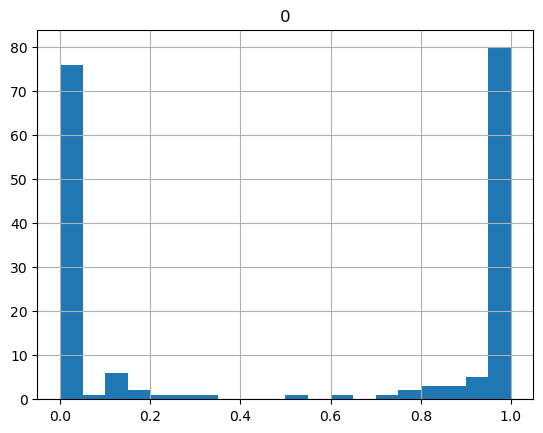

In [108]:
pd.DataFrame(nb.predict_proba(X_resampled)[:, 1] ).hist(bins=20)
plt.show()

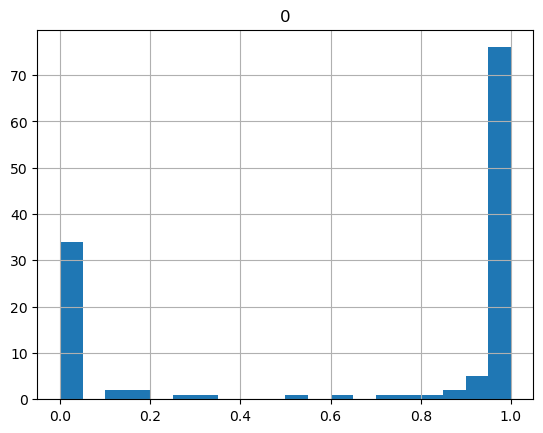

In [110]:
pd.DataFrame(nb.predict_proba(X)[:, 1] ).hist(bins=20)
plt.show()

## Understanding Calibration Curves

Classification model calibration refers to the process of aligning a model’s predicted probabilities with the actual observed frequencies of outcomes. Many classifiers can accurately predict which class an instance belongs to, but their confidence scores — the probabilities they output — are often not well calibrated. That means the numbers themselves do not reflect how likely the prediction is to be correct.

### What Is a Calibration Curve?

To assess whether a classifier's probabilities are well calibrated, we use a calibration curve. This curve plots:

    The mean predicted probability (e.g., 0.1, 0.2, ..., 0.9) on the x-axis.

    The actual observed frequency of positive labels among samples with that predicted probability on the y-axis.

For example, if the model predicts a 0.2 probability of the positive class for a group of samples, and in reality about 20% of those samples truly belong to the positive class, the model is well calibrated at that probability level.

A perfectly calibrated model produces a calibration curve that lies along the 45-degree diagonal — where predicted probabilities match observed frequencies. Deviations from this diagonal indicate overconfidence (curve lies below the diagonal) or underconfidence (curve lies above it).

Calibration curves are useful diagnostic tools to evaluate how trustworthy a model’s probability outputs are, especially in settings where probability estimates are used for downstream decisions, risk scoring, or thresholding.

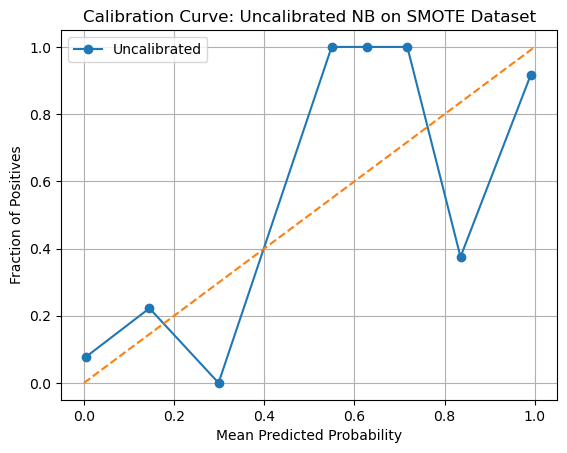

In [38]:
prob_true_uncal, prob_pred_uncal = calibration_curve(y_resampled, X_resampled_proba, n_bins=9)
plt.figure()
plt.plot(prob_pred_uncal, prob_true_uncal, marker='o', label='Uncalibrated')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve: Uncalibrated NB on SMOTE Dataset')
plt.legend()
plt.grid()
plt.show()

**Exercise:** Generate a calibration curve on the predictions of the NB classifier trained on the SMOTE dataset. How would you interpret and assess it's calibration? Are there ranges where it performs well, and those where it is poor?

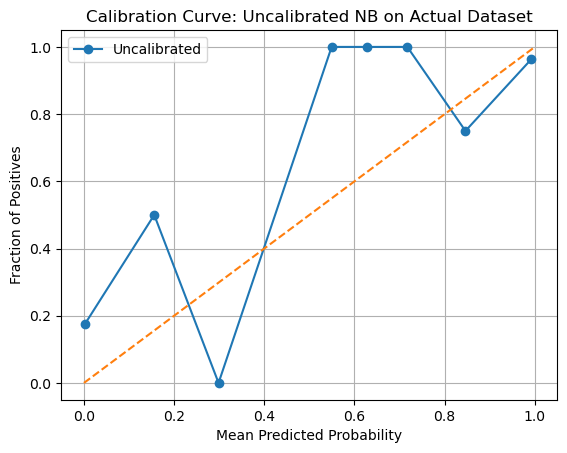

In [111]:
X_proba = nb.predict_proba(X)[:, 1] 
prob_true_uncal, prob_pred_uncal = calibration_curve(y, X_proba, n_bins=9)
plt.figure()
plt.plot(prob_pred_uncal, prob_true_uncal, marker='o', label='Uncalibrated')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve: Uncalibrated NB on Actual Dataset')
plt.legend()
plt.grid()
plt.show()

# Classification Model Calibration

Classification model calibration refers to the process of aligning a model’s predicted probabilities with the actual observed frequencies of outcomes. While many classifiers can accurately predict which class an instance belongs to, their estimated probabilities are often poorly calibrated — meaning the numeric confidence they assign does not reflect the true likelihood of correctness. For example, a classifier might assign a probability of 0.9 to many predictions, but only 70% of those may actually be correct.

A well-calibrated model should satisfy the following property: among all samples that are given a predicted probability of, say, 0.2 for the positive class, roughly 20% should actually belong to the positive class. This forms the basis of the calibration curve, which plots the predicted probabilities against the observed frequencies. A perfectly calibrated model produces a curve that closely follows the diagonal line, indicating that its confidence levels are statistically reliable.



## Train Classifier and Apply Platt Scaling (Logistic Regression)

We return to training our NB classifier using the SMOTE resampled dataset that is balanced. Naive Bayes is a fast, often accurate classifier, but its probabilities are usually not trustworthy out of the box - usually, this is the case because Naive Bayes assumes feature conditional independence, which is almost never true in practice. This is why calibration is crucial — especially when probabilities inform decisions, not just classification.

Usually, one would use but on small datasets like this, cross-validation-based calibration may do more harm than good. It's better to allocate a separate calibration set and fit a simple sigmoid once, rather than relying on noisy folds where the calibrator sees too few examples to learn from. Also, we trained our model on synthetic data to handle class imbalance, and the plan is then to use those predictions to fit a Platt scaler, while ideally we would fit the calibrator on different data to avoid overfitting, in this case we’re only evaluating the calibration on real, untouched data — so we still get a valid and interpretable calibration curve.

In [89]:
nb.fit(X_resampled, y_resampled)

GaussianNB()

## Extracting Log-Odds for Manual Platt Scaling

In this step, we are preparing the raw score from our training data that will serve as input to our Platt scaling calibrator. 

When we ask a probabilistic classifier to make predictions, it typically returns probabilities for each class. But these probabilities are usually the output of some internal decision function — for example, a logistic function applied to a raw, unbounded score. To calibrate these probabilities correctly, we need access to this raw score before it has been squashed into the [0, 1] range that is interpretable for us.

In the case of Naive Bayes, the model internally computes log-probabilities for each class. By taking the difference between the log-probabilities of class 1 and class 0, we obtain the log-odds, also called the logit score:

In [60]:
log_odds = nb.predict_log_proba(X_resampled)[:, 1] - nb.predict_log_proba(X_resampled)[:, 0]
log_odds

(array([  5.44207022,  -9.39451778,  10.77506377, -30.45240106,
          9.36810122,  -5.08410555,  11.14542873,   0.93042796,
          9.45032298,   5.5349071 ,  10.18441213,  -8.41263874,
          1.95326788,  -3.49364263,   0.52428953,  -6.16808149,
        -36.27150127,   8.67001514, -40.82581492,   7.6843089 ,
         11.04111576,   2.35103883,  10.44250017,  -5.30288389,
         11.00687728,  10.88055535,  -8.86026221,  -1.51016754,
          5.90468588,  11.24186021,  11.14542873, -11.16887013,
          5.82242324,  -6.37416962,  11.04534817,  10.5932257 ,
         -0.8228579 ,   3.27613842,   9.96624997,  -3.47525207,
          0.1978586 ,  -5.80074011,   2.31375652,   9.98892995,
          8.72413559,   6.50528778,   4.38381361,   5.38450984,
          5.10281904,   4.82452579, -14.19787447,   7.34093076,
        -35.37667189,  11.28161871,   3.37254346,   8.60719556,
          3.61371505,   3.52981359, -48.80777219,  11.14542873,
        -68.41015585, -35.62571008,   7.

**Exercise:** Visualise the distribution of the log odds above

array([[<Axes: title={'center': '0'}>]], dtype=object)

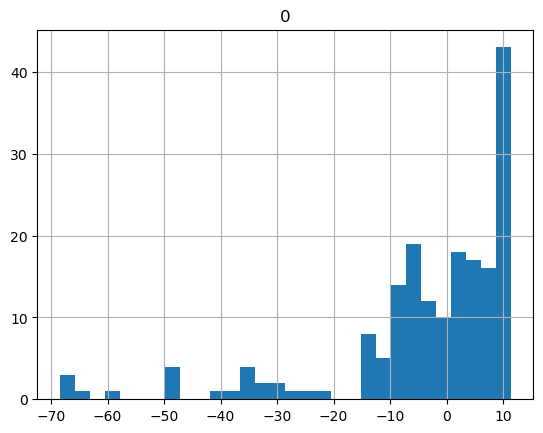

In [84]:
pd.DataFrame(log_odds).hist(bins=30)

We will use these log-odds as the input feature to a logistic regression model that performs Platt scaling — a post-hoc calibration method that maps log-odds to well-calibrated probabilities using a learned sigmoid function.

## Fitting a Logistic Regression Model for Platt Scaling

In this step, we are implementing Platt scaling, a commonly used technique for calibrating predicted probabilities. The purpose of this step is not to improve classification accuracy, but to make the model’s confidence scores more honest and trustworthy. Specifically, we want to adjust the uncalibrated probabilities produced by our classifier (in this case, a Naive Bayes model) so they better reflect the actual likelihood of a sample belonging to the positive class.

To do this, we use a simple model called logistic regression. Normally, logistic regression is used as a standalone classifier that makes predictions based on multiple input features. However, in the context of Platt scaling, we are using it in a more focused way: not as a full classifier, but as a curve-fitting tool.

Here, we are fitting logistic regression to a single input — the log-odds output by our Naive Bayes model. The log-odds represent how strongly the model prefers one class over another. What logistic regression does is learn a smooth S-shaped curve (called a sigmoid) that maps these raw log-odds values to calibrated probabilities — values between 0 and 1 that more accurately correspond to the true chances of being in the positive class. So we are fitting a logistic regression model — but in a slightly unconventional way. **We are not using it as a classifier over multiple input features**. Instead, we are using it to fit a sigmoid curve over a single score, the log-odds we computed earlier.

This step is essential when the original model tends to be overconfident or underconfident in its predictions. The logistic regression model will learn to correct these systematic biases, giving us probability outputs that are better aligned with observed outcomes.



In [62]:
platt = LogisticRegression(solver='lbfgs')
platt.fit(log_odds.reshape(-1, 1), y_resampled)

LogisticRegression()

Again, we fit this model using the SMOTE-resampled dataset labels y_resampled.

Why this works:

The logistic regression model learns the optimal parameters a (slope) and b (intercept) so that:

        When it sees a log-odds score from our base model,

        It outputs a probability that matches the actual observed frequency of the positive class.

This sigmoid acts as a correction layer: it does not change the ranking of predictions, but it adjusts their confidence to better match empirical outcomes.

After this step, we have a fitted Platt model that can take any log-odds value from our Naive Bayes classifier and return a calibrated probability.

## Applying the Platt Calibration Model to New Data

Now that we’ve trained a logistic regression model to perform Platt scaling on the log-odds, we are ready to apply it to new data. In our case, this "new" data is the original, imbalanced dataset that has not been augmented with SMOTE.

In [86]:
log_odds_test = nb.predict_log_proba(X)[:, 1] - nb.predict_log_proba(X)[:, 0]
log_odds_test

array([  5.44207022,  -9.39451778,  10.77506377, -30.45240106,
         9.36810122,  -5.08410555,  11.14542873,   0.93042796,
         9.45032298,   5.5349071 ,  10.18441213,  -8.41263874,
         1.95326788,  -3.49364263,   0.52428953,  -6.16808149,
       -36.27150127,   8.67001514, -40.82581492,   7.6843089 ,
        11.04111576,   2.35103883,  10.44250017,  -5.30288389,
        11.00687728,  10.88055535,  -8.86026221,  -1.51016754,
         5.90468588,  11.24186021,  11.14542873, -11.16887013,
         5.82242324,  -6.37416962,  11.04534817,  10.5932257 ,
        -0.8228579 ,   3.27613842,   9.96624997,  -3.47525207,
         0.1978586 ,  -5.80074011,   2.31375652,   9.98892995,
         8.72413559,   6.50528778,   4.38381361,   5.38450984,
         5.10281904,   4.82452579, -14.19787447,   7.34093076,
       -35.37667189,  11.28161871,   3.37254346,   8.60719556,
         3.61371505,   3.52981359, -48.80777219,  11.14542873,
       -68.41015585, -35.62571008,   7.03621006,   9.05

Why this is important:

    This step transforms the overconfident or poorly distributed probabilities from Naive Bayes into well-calibrated probabilities.

    These probabilities are now better aligned with the actual observed frequencies of class labels in the real data.

    This is crucial for applications where decision thresholds, risk scores, or expected utility depend on meaningful probability estimates — not just correct classifications.

Calibration doesn't change which class the model chooses, but it changes how confident the model says it is. In critical applications like medicine, law, or finance, this distinction matters — you don't just want the model to say “Yes,” you want it to say “Yes, and I'm 92% confident.”

## Extracting Calibrated Probabilities for the Positive Class

In this step, we are finalizing the output of our calibrated model by extracting the calibrated probability of the positive class for each sample in the original dataset.

In [90]:
calibrated_proba = platt.predict_proba(log_odds_test.reshape(-1, 1))[:, 1]

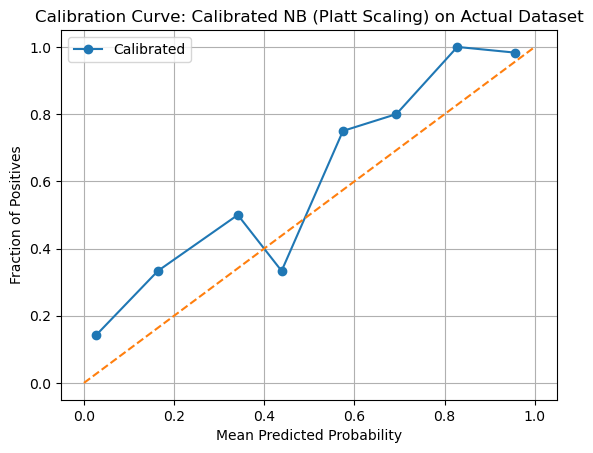

In [91]:
prob_true_cal, prob_pred_cal = calibration_curve(y, calibrated_proba, n_bins=8)
plt.figure()
plt.plot(prob_pred_cal, prob_true_cal, marker='o', label='Calibrated')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives')
plt.title('Calibration Curve: Calibrated NB (Platt Scaling) on Actual Dataset')
plt.legend()
plt.grid()
plt.show()


array([[<Axes: title={'center': '0'}>]], dtype=object)

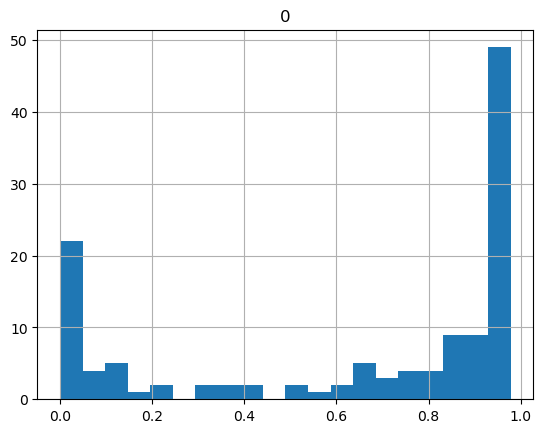

In [92]:
pd.DataFrame(calibrated_proba).hist(bins=20)

## So how accurate is the calibrated classifier?

In [113]:
print(classification_report(y, (platt.predict_proba(
                                    (nb.predict_log_proba(X)[:, 1] - nb.predict_log_proba(X)[:, 0]).reshape(-1, 1)
                                            )[:, 1] >= 0.5).astype(int)))

              precision    recall  f1-score   support

           0       0.78      0.89      0.83        36
           1       0.95      0.90      0.93        92

    accuracy                           0.90       128
   macro avg       0.87      0.90      0.88       128
weighted avg       0.91      0.90      0.90       128



Breaking it down:

    nb.predict_log_proba(X) → gets the log-probabilities for both classes.

    [:, 1] - [:, 0] → computes the log-odds.

    .reshape(-1, 1) → formats it for logistic regression input.

    platt.predict_proba(...)[..., 1] → gets the calibrated probability for class 1.

    >= 0.5 → applies a standard decision threshold to turn it into predicted class labels.

    classification_report(...) → compares these predicted labels to the true labels y.

Calibration adjusts probability scores, not the underlying classification mechanism. But you still need to apply a threshold (usually 0.5) to turn probabilities into class labels. If the probabilities become more realistic but conservative, some predictions that were previously confidently predicted as class 1 may now fall below the threshold and be classified as class 0, and vice versa.

This can slightly shift the decision boundary and lead to:

    A few previously correct predictions becoming incorrect

    A few overconfident predictions being corrected but now falling on the wrong side of the 0.5 line

Calibration prioritises the honesty of the model's confidence, not its ability to classify correctly.
It's possible for accuracy or F1 to dip slightly if the model's original probabilities were overconfident but led to "correct" decisions — calibration smooths those over, potentially pushing some just across the decision threshold.

So Was This a Good Calibration?

Yes — if the goal is reliable probabilities, this result is expected and acceptable:

    Your F1, precision, and recall stayed very strong.

    A minor drop in accuracy is a fair tradeoff for better-calibrated confidence.

    You should check calibration curves and Brier score — they will likely improve, which is the key success criterion for calibration.

Therefore, remember that after calibration, the model might make slightly fewer correct predictions, but its probability outputs are now statistically reliable. In high-stakes domains, it’s often better to have a cautious, honest model than an overconfident one — especially when those probabilities guide downstream actions or risk assessments.

## Brier score 

The Brier score is the standard numeric metric for evaluating probability calibration, and it’s especially well-suited to binary classification. It directly measures the accuracy of predicted probabilities, rather than class labels - it measures the mean squared error between the predicted probabilities and the actual outcomes.
$
\text{Brier Score} = \frac{1}{N} \sum_{i=1}^{N} \left( \hat{p}_i - y_i \right)^2
$

Where:
- $N$ is the total number of samples
- $ \hat{p}_i $ is the predicted probability of the positive class for sample $ i$
- $( y_i \in \{0, 1\} )$ is the true label of sample $i$

A lower Brier score indicates better calibrated and more accurate probability estimates. A score of 0 represents perfect predictions.


Interpretation:

    The Brier score ranges from 0 to 1, where:

        0 is perfect: predicted probabilities match the true outcomes exactly.

        Lower is better.

It penalises both overconfident wrong predictions and underconfident correct predictions.

The Brier score gives us a single number that tells how well our predicted probabilities match reality. Unlike accuracy, which just counts whether predictions were right, the Brier score cares about how close the model's confidence is to the truth. A lower Brier score after calibration means the model is not only making good predictions — it’s also honest about how confident it is.

**Exercise:** Look at the documentation and then apply the Brier score to both the uncalibrated and calibrated probabilities from the actual data

In [123]:
proba_uncal = nb.predict_proba(X)[:, 1]
proba_calib = calibrated_proba  

print("Brier score (uncalibrated):", brier_score_loss(y, proba_uncal))
print("Brier score (calibrated):", brier_score_loss(y, proba_calib))

Brier score (uncalibrated): 0.09019598663106083
Brier score (calibrated): 0.08479103983858016
